In [1]:
from gas.gas_circuit import GAS_HW, bin_to_int, GAS_dicke
from gas.dicke import dicke_state

/Users/tom/Documents/ucl/projects/GAS/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import numpy as np 
import json
import os 
import h5py
from qiskit_aer import StatevectorSimulator
from qiskit import transpile, QuantumCircuit

from symmer.operators.base import PauliwordOp, QuantumState

from sympy import var
import h5py
from itertools import combinations
import matplotlib.pyplot as plt

In [3]:
## load data
with h5py.File("H3_data.h5", "r") as infile:

    f_op = PauliwordOp(infile["F_true_symp_matrix"][()],
                       infile["F_true_coeff_vec"][()])

    f_op_rounded = PauliwordOp(infile["F_rounded_symp_matrix"][()],
                                infile["F_rounded_coeff_vec"][()])
    
    linear_true = dict(zip(infile["lin_true_keys"][()],
                       infile["lin_true_values"][()]))
    
    quad_true = dict(zip( [(a,b) for a,b in infile["quad_true_keys"][()]],
                       infile["quad_true_values"][()]))
    

    linear_rounded = dict(zip(infile["lin_rounded_keys"][()],
                    infile["lin_rounded_values"][()]))
    
    quad_rounded   = dict(zip([(a,b) for a,b in infile["quad_rounded_keys"][()]],
                         infile["quad_rounded_values"][()]))
    
    n_elec = infile["SCF_nelec"][()]
    basis_set = infile["SCF_basis"][()]
    n_spin = 2*infile["h1e_MO"][()].shape[0]

print("LOADED")

LOADED


In [4]:
### write QUBO problem!
variables = [var(f'x{q_idx}', bool=True) for q_idx in range(n_spin)]

problem_fn = 0
for q_idx, coeff in linear_rounded.items():
    problem_fn+= variables[q_idx]*coeff

for (q_idx1, q_idx2), coeff in quad_rounded.items():
    problem_fn+= variables[q_idx1]*variables[q_idx2]*coeff

problem_fn

4.0*x0*x1 + 4.0*x0*x2 + 4.0*x0*x3 + 4.0*x0*x4 + 4.0*x0*x5 - 14.0*x0 + 4.0*x1*x2 + 4.0*x1*x3 + 4.0*x1*x4 + 4.0*x1*x5 - 14.0*x1 + 4.0*x2*x3 + 4.0*x2*x4 + 4.0*x2*x5 - 10.0*x2 + 4.0*x3*x4 + 4.0*x3*x5 - 10.0*x3 + 8.0*x4*x5 - 6.0*x4 - 6.0*x5

In [5]:
## go through all valid solutions (classical brute force)

def n_choose_k_vectors(n: int, k: int):
    return np.array(
        [
            [int(i in comb) for i in range(n)]
            for comb in combinations(np.arange(n), k)
        ]
    )

alph_bitstrings = n_choose_k_vectors(f_op.n_qubits//2, n_elec[0])
beta_bitstrings = n_choose_k_vectors(f_op.n_qubits//2, n_elec[1])

eigstate_and_vals = dict()
for alpha_term in alph_bitstrings:
    for beta_term in beta_bitstrings:
        state = np.vstack((alpha_term, beta_term)).T.reshape([f_op.n_qubits]) 
        evaluated = int(problem_fn.subs(zip(variables, state)))
        # print(int(evaluated))
        eigstate_and_vals[tuple(state.tolist())] = evaluated
eigstate_and_vals

{(1, 1, 1, 1, 0, 0): -24,
 (1, 1, 1, 0, 0, 1): -20,
 (1, 0, 1, 1, 0, 1): -16,
 (1, 1, 0, 1, 1, 0): -20,
 (1, 1, 0, 0, 1, 1): -12,
 (1, 0, 0, 1, 1, 1): -8,
 (0, 1, 1, 1, 1, 0): -16,
 (0, 1, 1, 0, 1, 1): -8,
 (0, 0, 1, 1, 1, 1): -4}

In [6]:
nq_qubo = f_op.n_qubits
maxval_qubo = np.abs(list(linear_rounded.values())).sum() + np.abs(list(quad_rounded.values())).sum()

print(f"number of QUBO qubits: {nq_qubo}")
print(f"maximum QUBO value possible: {maxval_qubo}")

number of QUBO qubits: 6
maximum QUBO value possible: 124.0


In [7]:
nq_fx = int(np.ceil(np.log2(maxval_qubo))) + 1 # add one for negative values
print(f"maximum of f(x) qubits: {nq_fx}")

## get binary value for all 1s state (max value) for na and nb counts!
nq_na = int(np.ceil(np.log2(bin_to_int(np.array([1]* (nq_qubo//2)))))) 
nq_nb = int(np.ceil(np.log2(bin_to_int(np.array([1]* (nq_qubo//2)))))) 

print(f"maximum of Na(x) qubits: {nq_na}") # alpha electrons
print(f"maximum of Nb(x) qubits: {nq_nb}") # beta electrons

## get binary value for all 1s state (max value) for na and nb counts!
na_target = int(n_elec[0])
nb_target = int(n_elec[1])


maximum of f(x) qubits: 8
maximum of Na(x) qubits: 3
maximum of Nb(x) qubits: 3


In [8]:
total_nq = nq_qubo + nq_fx + nq_na + nq_nb + 3
print(f"total number of qubits in GAS-SCF (non-Dicke): {total_nq}")

total number of qubits in GAS-SCF (non-Dicke): 23


In [9]:
gas_obj = GAS_HW( nq_qubo, 
                        nq_fx,
                        nq_na,
                        nq_nb,
                        linear_rounded,
                        quad_rounded,
                        na_target,
                        nb_target)

In [10]:
# Let us do a single repeat 
# with the worst solution... y = -4

n_repeats = 1 
full_circuit = gas_obj.build_circuit(4, n_repeats) # -y = --4 = 4

# Simulate QC 
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_circuit.decompose().decompose())

statevec = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec[np.abs(statevec)<1e-15] = 0 # zero out vanishingly small terms!
psi_out = QuantumState.from_array(statevec)

## slice out only QUBO register qubits
psi_out = QuantumState(psi_out.state_matrix[:, -f_op.n_qubits:],
                       np.abs(psi_out.state_op.coeff_vec)).cleanup().normalize.sort()
psi_out

 0.313+0.000j |101101> +
 0.313+0.000j |011110> +
 0.312+0.000j |100111> +
 0.312+0.000j |111001> +
 0.312+0.000j |011011> +
 0.312+0.000j |001111> +
 0.312+0.000j |110011> +
 0.312+0.000j |110110> +
 0.063+0.000j |000001> +
 0.063+0.000j |000010> +
 0.063+0.000j |001000> +
 0.063+0.000j |001100> +
 0.063+0.000j |000000> +
 0.063+0.000j |000011> +
 0.063+0.000j |010000> +
 0.063+0.000j |011000> +
 0.063+0.000j |100001> +
 0.063+0.000j |001010> +
 0.063+0.000j |010001> +
 0.063+0.000j |010010> +
 0.063+0.000j |000100> +
 0.063+0.000j |000101> +
 0.063+0.000j |100000> +
 0.063+0.000j |001001> +
 0.063+0.000j |000110> +
 0.063+0.000j |100100> +
 0.063+0.000j |100010> +
 0.063+0.000j |010100> +
 0.063+0.000j |010011> +
 0.063+0.000j |110000> +
 0.063+0.000j |101000> +
 0.063+0.000j |110010> +
 0.063+0.000j |110001> +
 0.063+0.000j |010110> +
 0.062+0.000j |001011> +
 0.062+0.000j |001110> +
 0.062+0.000j |001101> +
 0.062+0.000j |000111> +
 0.062+0.000j |100011> +
 0.062+0.000j |011010> +


In [11]:
full_circuit.num_qubits

23

In [12]:
# Let us use the SAME circuit BUT with more repeats
n_repeats = 2 #<--incerased


full_circuit = gas_obj.build_circuit(4, n_repeats) 
# Simulate QC 
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_circuit.decompose().decompose())

statevec = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec[np.abs(statevec)<1e-15] = 0 # zero out vanishingly small terms!
psi_out = QuantumState.from_array(statevec)

## slice out only QUBO register qubits
psi_out2 = QuantumState(psi_out.state_matrix[:, -f_op.n_qubits:],
                       np.abs(psi_out.state_op.coeff_vec)).cleanup().normalize.sort()
psi_out2

 0.344+0.000j |101101> +
 0.344+0.000j |100111> +
 0.344+0.000j |011110> +
 0.344+0.000j |011011> +
 0.344+0.000j |001111> +
 0.344+0.000j |111001> +
 0.344+0.000j |110110> +
 0.344+0.000j |110011> +
 0.031+0.000j |000001> +
 0.031+0.000j |000010> +
 0.031+0.000j |000011> +
 0.031+0.000j |001000> +
 0.031+0.000j |001100> +
 0.031+0.000j |100001> +
 0.031+0.000j |011000> +
 0.031+0.000j |010011> +
 0.031+0.000j |000000> +
 0.031+0.000j |100000> +
 0.031+0.000j |001010> +
 0.031+0.000j |000100> +
 0.031+0.000j |100100> +
 0.031+0.000j |100010> +
 0.031+0.000j |000101> +
 0.031+0.000j |010001> +
 0.031+0.000j |110010> +
 0.031+0.000j |010000> +
 0.031+0.000j |001001> +
 0.031+0.000j |000110> +
 0.031+0.000j |101000> +
 0.031+0.000j |110000> +
 0.031+0.000j |100011> +
 0.031+0.000j |100110> +
 0.031+0.000j |010010> +
 0.031+0.000j |000111> +
 0.031+0.000j |001101> +
 0.031+0.000j |010100> +
 0.031+0.000j |110001> +
 0.031+0.000j |010110> +
 0.031+0.000j |001011> +
 0.031+0.000j |101010> +


In [13]:
# We can see that in both cases the amplitude of the desired bitstrings has been increased.
# Next let us improve y (for example to the second best value - see eigstate_and_vals above)

In [14]:
# single repeat
# y = 20

n_repeats = 1 
full_circuit = gas_obj.build_circuit(20, n_repeats) # -y = --20 = 20

# Simulate QC 
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_circuit.decompose().decompose())

statevec = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec[np.abs(statevec)<1e-15] = 0 # zero out vanishingly small terms!
psi_out = QuantumState.from_array(statevec)

## slice out only QUBO register qubits
psi_out3 = QuantumState(psi_out.state_matrix[:, -f_op.n_qubits:],
                       np.abs(psi_out.state_op.coeff_vec)).cleanup().normalize.sort()
psi_out3

 0.367+0.000j |001111> +
 0.117+0.000j |000000> +
 0.117+0.000j |000010> +
 0.117+0.000j |000011> +
 0.117+0.000j |001000> +
 0.117+0.000j |010000> +
 0.117+0.000j |100001> +
 0.117+0.000j |100000> +
 0.117+0.000j |001100> +
 0.117+0.000j |010010> +
 0.117+0.000j |000001> +
 0.117+0.000j |110000> +
 0.117+0.000j |000100> +
 0.117+0.000j |100100> +
 0.117+0.000j |001001> +
 0.117+0.000j |000110> +
 0.117+0.000j |010001> +
 0.117+0.000j |010011> +
 0.117+0.000j |011000> +
 0.117+0.000j |000101> +
 0.117+0.000j |100010> +
 0.117+0.000j |010100> +
 0.117+0.000j |101000> +
 0.117+0.000j |110010> +
 0.117+0.000j |000111> +
 0.117+0.000j |100011> +
 0.117+0.000j |001010> +
 0.117+0.000j |110011> +
 0.117+0.000j |001101> +
 0.117+0.000j |001011> +
 0.117+0.000j |011001> +
 0.117+0.000j |001110> +
 0.117+0.000j |110001> +
 0.117+0.000j |010110> +
 0.117+0.000j |100110> +
 0.117+0.000j |111000> +
 0.117+0.000j |110100> +
 0.117+0.000j |011010> +
 0.117+0.000j |011100> +
 0.117+0.000j |011110> +


In [15]:
# as we are thresholding by the second best value, only the optimal state will be boosted

In [16]:
# Let us increase the number of repeats
# y = 20

n_repeats = 6 #<-- increased
full_circuit = gas_obj.build_circuit(20, n_repeats) # -y = --20 = 20

# Simulate QC 
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_circuit.decompose().decompose())

statevec = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec[np.abs(statevec)<1e-15] = 0 # zero out vanishingly small terms!
psi_out = QuantumState.from_array(statevec)

## slice out only QUBO register qubits
psi_out4 = QuantumState(psi_out.state_matrix[:, -f_op.n_qubits:],
                       np.abs(psi_out.state_op.coeff_vec)).cleanup().normalize.sort()
psi_out4

 0.998+0.000j |001111> +
 0.007+0.000j |000000> +
 0.007+0.000j |000011> +
 0.007+0.000j |110011> +
 0.007+0.000j |001000> +
 0.007+0.000j |010111> +
 0.007+0.000j |001110> +
 0.007+0.000j |000010> +
 0.007+0.000j |010011> +
 0.007+0.000j |011011> +
 0.007+0.000j |010000> +
 0.007+0.000j |100001> +
 0.007+0.000j |000100> +
 0.007+0.000j |000111> +
 0.007+0.000j |001101> +
 0.007+0.000j |010010> +
 0.007+0.000j |101000> +
 0.007+0.000j |010101> +
 0.007+0.000j |110110> +
 0.007+0.000j |100010> +
 0.007+0.000j |010100> +
 0.007+0.000j |100100> +
 0.007+0.000j |011000> +
 0.007+0.000j |011001> +
 0.007+0.000j |100011> +
 0.007+0.000j |101110> +
 0.007+0.000j |110000> +
 0.007+0.000j |110001> +
 0.007+0.000j |011110> +
 0.007+0.000j |001011> +
 0.007+0.000j |010110> +
 0.007+0.000j |111001> +
 0.007+0.000j |100110> +
 0.007+0.000j |001010> +
 0.007+0.000j |010001> +
 0.007+0.000j |001100> +
 0.007+0.000j |111010> +
 0.007+0.000j |000001> +
 0.007+0.000j |110010> +
 0.007+0.000j |011010> +


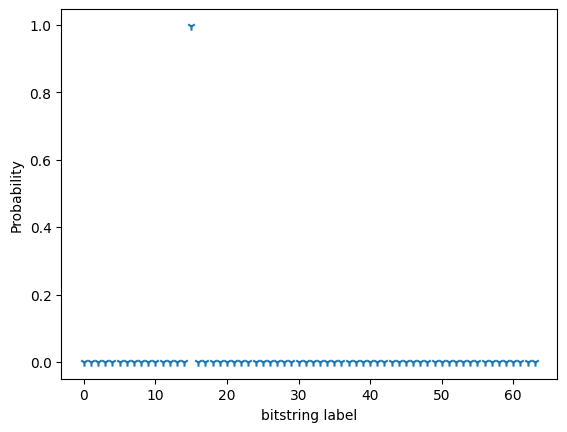

In [17]:
probabilities = np.abs(psi_out4.state_op.coeff_vec)**2
labels = (psi_out4.state_matrix * 1<<np.arange(psi_out4.n_qubits)[::-1]).sum(axis=1)
# plt.title("L=6")
plt.scatter(labels, probabilities, marker='1')
plt.xlabel("bitstring label")
plt.ylabel("Probability")
plt.show()

In [18]:
# we find that going from 1-6 the amplitude of the desired state increases
# but at 7 repeats we are over rotating

In [19]:
## Let us build all these:

repeat_list = np.arange(1,10)
output_states_list = []
for rep in repeat_list:
    full_circuit = gas_obj.build_circuit(20, rep) # -y = --20 = 20

    # Simulate QC 
    simulator_aerlegacy = StatevectorSimulator()
    result_aerlegacy = simulator_aerlegacy.run(full_circuit.decompose().decompose())

    statevec = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
    statevec[np.abs(statevec)<1e-15] = 0 # zero out vanishingly small terms!
    psi_out = QuantumState.from_array(statevec)

    ## slice out only QUBO register qubits
    psi_out5 = QuantumState(psi_out.state_matrix[:, -f_op.n_qubits:],
                        np.abs(psi_out.state_op.coeff_vec)).cleanup().normalize.sort()
    
    output_states_list.append(psi_out5)

Text(0, 0.5, 'Probability')

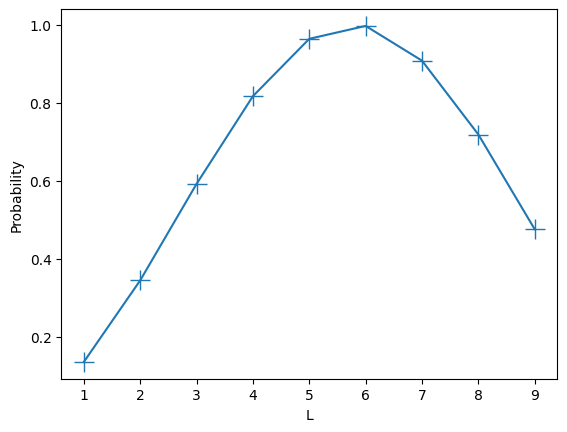

In [20]:
largest_amp_list = [np.abs(psi.state_op.coeff_vec[0])**2 for psi in output_states_list]
largest_bitstring = [psi[0] for psi in output_states_list]

plt.plot(repeat_list, largest_amp_list, marker="+", markersize=15)
plt.xlabel("L")
plt.ylabel("Probability")

In [21]:
### check to see bitstring is correct!
largest_bitstring

[ 0.367+0.000j |001111>,
  0.586+0.000j |001111>,
  0.769+0.000j |001111>,
  0.904+0.000j |001111>,
  0.982+0.000j |001111>,
  0.998+0.000j |001111>,
  0.953+0.000j |001111>,
  0.847+0.000j |001111>,
  0.689+0.000j |001111>]

# Dicke Version

In [23]:
alph_dicke = dicke_state(nq_qubo//2, na_target).to_gate()
beta_dicke = dicke_state(nq_qubo//2, nb_target).to_gate()

full_dicke = QuantumCircuit(nq_qubo)
full_dicke.append(alph_dicke, [2*qi for qi in range(nq_qubo//2)])
full_dicke.append(beta_dicke, [2*qi+1 for qi in range(nq_qubo//2)])

full_dicke = transpile(full_dicke, basis_gates=['id', 'ry', 'rx', 'cx'], optimization_level=1, seed_transpiler=1) 

In [24]:
# Show output of Dicke circuit 
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_dicke.decompose().decompose())

statevec_dicke = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec_dicke[np.abs(statevec_dicke)<1e-15] = 0 # zero out vanishingly small terms!
psi_dicke = QuantumState.from_array(statevec_dicke)
psi_dicke

 0.333+0.000j |001111> +
 0.333+0.000j |011011> +
 0.333+0.000j |011110> +
 0.333+0.000j |100111> +
 0.333+0.000j |101101> +
 0.333+0.000j |110011> +
 0.333+0.000j |110110> +
 0.333+0.000j |111001> +
 0.333+0.000j |111100>

In [25]:
## base object for Dicke GAS
gas_obj_dicke = GAS_dicke( nq_qubo, 
                        nq_fx,
                        linear_rounded,
                        quad_rounded,
                        full_dicke)

In [26]:
### repeating above
### here we set repeats to be 1
### and y=-4


n_repeats = 1
full_circuit2 = gas_obj_dicke.build_circuit(4, n_repeats)


# Simulator 
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_circuit2.decompose().decompose())

statevec2 = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec2[np.abs(statevec2)<1e-15] = 0 # zero out vanishingly small terms!
psi_out2 = QuantumState.from_array(statevec2)


psi_out6 = QuantumState(psi_out2.state_matrix[:, -f_op.n_qubits:],
                       np.abs(psi_out2.state_op.coeff_vec)).cleanup().normalize.sort()

In [27]:
full_circuit2.num_qubits

14

In [28]:
# gas_obj_dicke.qc_reflect.draw()

In [29]:
psi_out6

 0.852+0.000j |111100> +
 0.185+0.000j |110011> +
 0.185+0.000j |110110> +
 0.185+0.000j |111001> +
 0.185+0.000j |011110> +
 0.185+0.000j |011011> +
 0.185+0.000j |101101> +
 0.185+0.000j |100111> +
 0.185+0.000j |001111>

In [30]:
## note we actually boosted the WRONG state here! (the -4 eigenstate)
## this is happening because the number of marked states is more than unmarked states
## this therefore affects the reflection operation and actually amplifies the unmarked state

## However, as this is such a SMALL problem these effects should not be present in most scenarios
## where the number of marked states is larger than non-marked states

## We see that if we increase the threshold then this no long occurs!

In [31]:
## we keep the number of repeats to 1
## but set y=-18

n_repeats = 1
full_circuit2 = gas_obj_dicke.build_circuit(18, #<-- increased
                                             n_repeats)


# Simulator 
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_circuit2.decompose().decompose())

statevec2 = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec2[np.abs(statevec2)<1e-15] = 0 # zero out vanishingly small terms!
psi_out2 = QuantumState.from_array(statevec2)


psi_out7 = QuantumState(psi_out2.state_matrix[:, -f_op.n_qubits:],
                       np.abs(psi_out2.state_op.coeff_vec)).cleanup().normalize.sort()

psi_out7

 0.556+0.000j |100111> +
 0.556+0.000j |001111> +
 0.556+0.000j |011011> +
 0.111+0.000j |111001> +
 0.111+0.000j |110011> +
 0.111+0.000j |110110> +
 0.111+0.000j |101101> +
 0.111+0.000j |011110> +
 0.111+0.000j |111100>

In [32]:
## now if we increase the number of repreats we should see the amp of marked states go up

n_repeats = 6
full_circuit2 = gas_obj_dicke.build_circuit(18,
                                             n_repeats)


# Simulator 
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_circuit2.decompose().decompose())

statevec2 = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec2[np.abs(statevec2)<1e-15] = 0 # zero out vanishingly small terms!
psi_out2 = QuantumState.from_array(statevec2)


psi_out8 = QuantumState(psi_out2.state_matrix[:, -f_op.n_qubits:],
                       np.abs(psi_out2.state_op.coeff_vec)).cleanup().normalize.sort()

psi_out8

 0.571+0.000j |100111> +
 0.571+0.000j |001111> +
 0.571+0.000j |011011> +
 0.060+0.000j |011110> +
 0.060+0.000j |101101> +
 0.060+0.000j |110110> +
 0.060+0.000j |110011> +
 0.060+0.000j |111001> +
 0.060+0.000j |111100>

In [33]:
## next let us threshold on y=-20
## so that only the G.S will be marked

n_repeats = 1
full_circuit2 = gas_obj_dicke.build_circuit(20,
                                             n_repeats)


# Simulator 
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_circuit2.decompose().decompose())

statevec2 = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec2[np.abs(statevec2)<1e-15] = 0 # zero out vanishingly small terms!
psi_out2 = QuantumState.from_array(statevec2)


psi_out8 = QuantumState(psi_out2.state_matrix[:, -f_op.n_qubits:],
                       np.abs(psi_out2.state_op.coeff_vec)).cleanup().normalize.sort()

psi_out8

 0.852+0.000j |001111> +
 0.185+0.000j |110011> +
 0.185+0.000j |110110> +
 0.185+0.000j |111001> +
 0.185+0.000j |111100> +
 0.185+0.000j |011110> +
 0.185+0.000j |101101> +
 0.185+0.000j |100111> +
 0.185+0.000j |011011>

In [34]:
## if we increase the number of repeats we should see the amp of the marked state go up

n_repeats = 2
full_circuit2 = gas_obj_dicke.build_circuit(20,
                                             n_repeats)


# Simulator 
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_circuit2.decompose().decompose())

statevec2 = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec2[np.abs(statevec2)<1e-15] = 0 # zero out vanishingly small terms!
psi_out2 = QuantumState.from_array(statevec2)


psi_out8 = QuantumState(psi_out2.state_matrix[:, -f_op.n_qubits:],
                       np.abs(psi_out2.state_op.coeff_vec)).cleanup().normalize.sort()

psi_out8

 0.992+0.000j |001111> +
 0.045+0.000j |110011> +
 0.045+0.000j |011110> +
 0.045+0.000j |110110> +
 0.045+0.000j |111100> +
 0.045+0.000j |111001> +
 0.045+0.000j |100111> +
 0.045+0.000j |101101> +
 0.045+0.000j |011011>

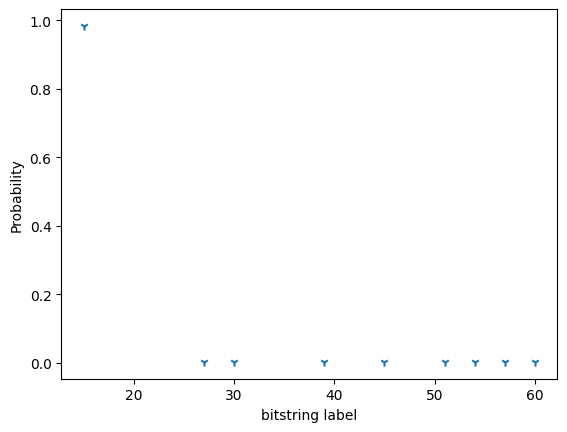

In [35]:
probabilities2 = np.abs(psi_out8.state_op.coeff_vec)**2
labels2 = (psi_out8.state_matrix * 1<<np.arange(psi_out8.n_qubits)[::-1]).sum(axis=1)
# plt.title("L=6")
plt.scatter(labels2, probabilities2, marker='1')
plt.xlabel("bitstring label")
plt.ylabel("Probability")
plt.show()

In [36]:
## Let us loop over different numbers of repeats for this circuit

repeat_list_dicke = np.arange(1,10)
output_states_list_dicke = []
for rep in repeat_list_dicke:

    full_circuit2 = gas_obj_dicke.build_circuit(20,
                                                 rep)


    # Simulator 
    simulator_aerlegacy = StatevectorSimulator()
    result_aerlegacy = simulator_aerlegacy.run(full_circuit2.decompose().decompose())

    statevec2 = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
    statevec2[np.abs(statevec2)<1e-15] = 0 # zero out vanishingly small terms!
    psi_out2 = QuantumState.from_array(statevec2)

    ## slice out only QUBO register qubits
    psi_out9 = QuantumState(psi_out2.state_matrix[:, -f_op.n_qubits:],
                        np.abs(psi_out2.state_op.coeff_vec)).cleanup().normalize.sort()
    
    output_states_list_dicke.append(psi_out9)

Text(0, 0.5, 'Probability')

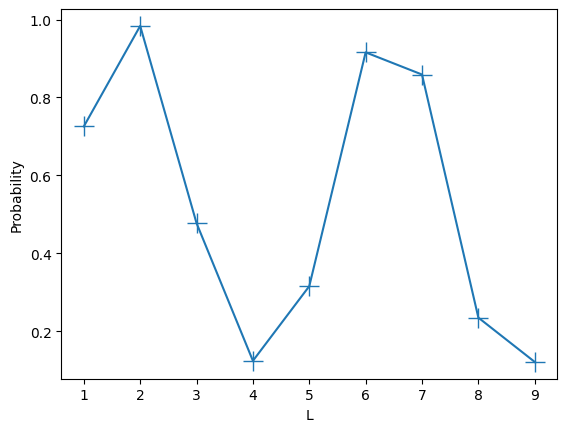

In [37]:
largest_amp_list_dicke = [np.abs(psi.state_op.coeff_vec[0])**2 for psi in output_states_list_dicke]
largest_bitstring_dicke = [psi[0] for psi in output_states_list_dicke]

plt.plot(repeat_list_dicke, largest_amp_list_dicke, marker="+", markersize=15)
plt.xlabel("L")
plt.ylabel("Probability")

In [38]:
largest_bitstring_dicke

[ 0.852+0.000j |001111>,
  0.992+0.000j |001111>,
  0.691+0.000j |001111>,
  0.352+0.000j |111100>,
  0.562+0.000j |001111>,
  0.957+0.000j |001111>,
  0.927+0.000j |001111>,
  0.485+0.000j |001111>,
  0.348+0.000j |111100>]

In [ ]:
## Note because of the over and under roations in Grover we can actually get the WRONG state out
## care is therefore necessary when using

In [ ]:
### optional is to SAVE the data uncomment here

# ## save output states!
# with h5py.File("H3_output_non_dicke.h5", "w") as outf:
#     for idx, psi in enumerate(output_states_list):
#         outf.create_dataset(f"psi_{idx}_state_matrix", data=psi.state_matrix)
#         outf.create_dataset(f"psi_{idx}_coeff_vec", data=psi.state_op.coeff_vec)

# with h5py.File("H3_output_dicke.h5", "w") as outf:
#     for idx, psi in enumerate(output_states_list_dicke):
#         outf.create_dataset(f"psi_{idx}_state_matrix", data=psi.state_matrix)
#         outf.create_dataset(f"psi_{idx}_coeff_vec", data=psi.state_op.coeff_vec)